In [2]:
import pandas as pd
import numpy as np
from sklearn.datasets import load_wine

# 1.1 Load Wine dataset from scikit-learn
wine_data = load_wine()
X_raw = wine_data.data
y = wine_data.target

# 1.2 Create the data frame for features
X = pd.DataFrame(X_raw, columns=wine_data.feature_names)

# Display required dataset overviews and class label mappings
print("--- 1. First Five Rows of Features (X) ---")
display(X.head())

print("\n--- 2. Dataset Shape ---")
print(f"Shape of X: {X.shape}")

print("\n--- 3. Feature Names ---")
print(X.columns.tolist())

print("\n--- 4. Target Labels (Unique) ---")
print(np.unique(y))

print("\n--- 5. Target Names ---")
print(wine_data.target_names)

print("\n--- 6. Number of Samples in Each Class ---")
class_counts = pd.Series(y).value_counts().sort_index()
for class_id, count in class_counts.items():
    print(f"Class {class_id} ({wine_data.target_names[class_id]}): {count} samples")

--- 1. First Five Rows of Features (X) ---


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0



--- 2. Dataset Shape ---
Shape of X: (178, 13)

--- 3. Feature Names ---
['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']

--- 4. Target Labels (Unique) ---
[0 1 2]

--- 5. Target Names ---
['class_0' 'class_1' 'class_2']

--- 6. Number of Samples in Each Class ---
Class 0 (class_0): 59 samples
Class 1 (class_1): 71 samples
Class 2 (class_2): 48 samples


In [3]:
# 2.1 Missing values and duplicates
missing_values = X.isnull().sum()
duplicate_rows = X.duplicated().sum()

print("--- Missing Value Counts Per Column ---")
print(missing_values)
print(f"\nNumber of Duplicate Rows: {duplicate_rows}")
if duplicate_rows == 0:
    print("No duplicate rows are present in the Wine dataset.")

# 2.2 Potential outliers using IQR
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1
outliers_count = ((X < (Q1 - 1.5 * IQR)) | (X > (Q3 + 1.5 * IQR))).sum()

print("\n--- Potential Outliers Count Per Feature (IQR Method) ---")
print(outliers_count)

# 2.3 Data types
print("\n--- Feature Data Types and Counts ---")
print(X.dtypes)
numeric_count = X.select_dtypes(include=['number']).shape[1]
categorical_count = X.select_dtypes(exclude=['number']).shape[1]
print(f"Number of Numerical Features: {numeric_count}")
print(f"Number of Categorical Features: {categorical_count}")

--- Missing Value Counts Per Column ---
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
dtype: int64

Number of Duplicate Rows: 0
No duplicate rows are present in the Wine dataset.

--- Potential Outliers Count Per Feature (IQR Method) ---
alcohol                         0
malic_acid                      3
ash                             3
alcalinity_of_ash               4
magnesium                       4
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 2
color_intensity                 4
hue                       

--- Descriptive Statistics ---
                                    Mean   Median     Min      Max  \
alcohol                        13.000618   13.050   11.03    14.83   
malic_acid                      2.336348    1.865    0.74     5.80   
ash                             2.366517    2.360    1.36     3.23   
alcalinity_of_ash              19.494944   19.500   10.60    30.00   
magnesium                      99.741573   98.000   70.00   162.00   
total_phenols                   2.295112    2.355    0.98     3.88   
flavanoids                      2.029270    2.135    0.34     5.08   
nonflavanoid_phenols            0.361854    0.340    0.13     0.66   
proanthocyanins                 1.590899    1.555    0.41     3.58   
color_intensity                 5.058090    4.690    1.28    13.00   
hue                             0.957449    0.965    0.48     1.71   
od280/od315_of_diluted_wines    2.611685    2.780    1.27     4.00   
proline                       746.893258  673.500  278.00  

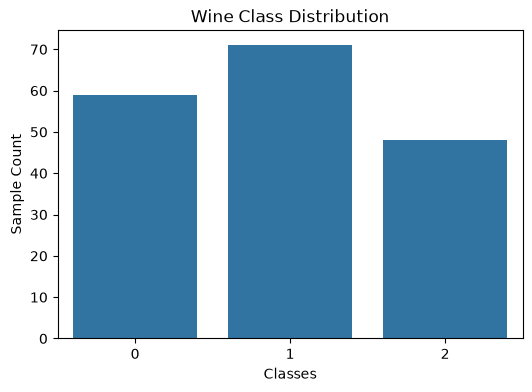

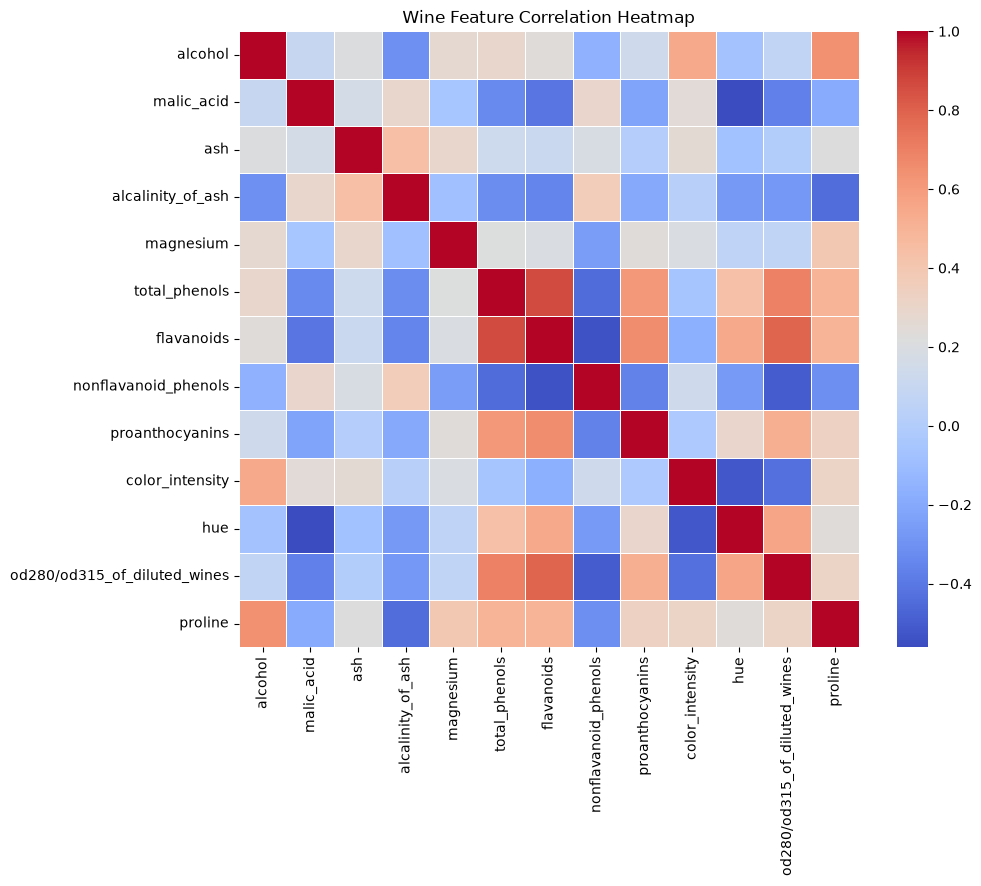

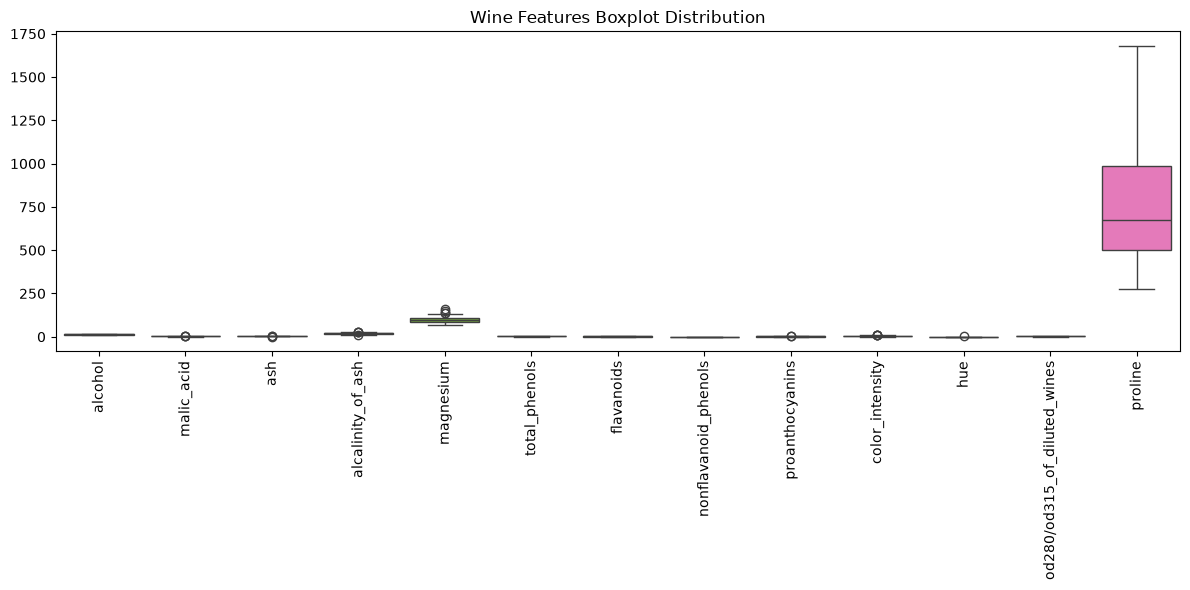

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# 3.1 Descriptive statistics
desc_stats = pd.DataFrame({
    'Mean': X.mean(),
    'Median': X.median(),
    'Min': X.min(),
    'Max': X.max(),
    'Std': X.std(),
    'Q1': X.quantile(0.25),
    'Q3': X.quantile(0.75)
})
print("--- Descriptive Statistics ---")
print(desc_stats)

# 3.2 Class distribution plot
plt.figure(figsize=(6, 4))
sns.countplot(x=y)
plt.title("Wine Class Distribution")
plt.xlabel("Classes")
plt.ylabel("Sample Count")
plt.show()

# Pearson feature-correlation heatmap
plt.figure(figsize=(10, 8))
correlation_matrix = X.corr()
sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', linewidths=0.5)
plt.title("Wine Feature Correlation Heatmap")
plt.show()

# 3.3 Boxplots for all features
plt.figure(figsize=(12, 6))
sns.boxplot(data=X)
plt.xticks(rotation=90)
plt.title("Wine Features Boxplot Distribution")
plt.tight_layout()
plt.show()

In [5]:
from sklearn.model_selection import train_test_split

# 4.1 Fix the test set (20% test set once) and repeat the training/validation split
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

# Keep track of fixed test indices
test_indices = X_test.index

# Define seeds as requested
SEEDS = [42, 52, 62]
splits = {}

for seed in SEEDS:
    # Split the 80% into training (~70% of total) and validation (~10% of total)
    # test_size=0.125 on the 80% data equals 10% of the full dataset.
    X_tr, X_val, y_tr, y_val = train_test_split(
        X_train_val, y_train_val, 
        test_size=0.125, 
        stratify=y_train_val, 
        random_state=seed
    )
    
    splits[seed] = {
        'X_train': X_tr, 'X_val': X_val, 
        'y_train': y_tr, 'y_val': y_val
    }

# 4.2 Verify the split
print("--- 4.2 Split Verification Summary ---")
print(f"Total dataset samples: {X.shape[0]}")
print(f"Fixed Test set samples: {X_test.shape[0]} ({(X_test.shape[0]/X.shape[0])*100:.1f}%)")

for seed in SEEDS:
    tr_len = len(splits[seed]['X_train'])
    val_len = len(splits[seed]['X_val'])
    total_sum = tr_len + val_len + len(X_test)
    print(f"Seed {seed} -> Train: {tr_len}, Validation: {val_len}, Test: {len(X_test)} | Sum: {total_sum}")

--- 4.2 Split Verification Summary ---
Total dataset samples: 178
Fixed Test set samples: 36 (20.2%)
Seed 42 -> Train: 124, Validation: 18, Test: 36 | Sum: 178
Seed 52 -> Train: 124, Validation: 18, Test: 36 | Sum: 178
Seed 62 -> Train: 124, Validation: 18, Test: 36 | Sum: 178


In [6]:
from sklearn.preprocessing import StandardScaler

# 5.1 Handle missing values (Wine dataset has no missing values)
print("--- 5.1 Missing Values Check ---")
print(f"Total missing values in X_train_val: {X_train_val.isnull().sum().sum()}")
print("No missing values found. Imputation step is skipped as instructed.")

# 5.2 Select one scaler (StandardScaler)
scaler_type = StandardScaler

# 5.3 Fit and apply the scaler correctly
scaled_splits = {}

for seed in SEEDS:
    scaler = scaler_type()
    
    # Fit ONLY on the training features of this specific seed
    X_tr_scaled = pd.DataFrame(
        scaler.fit_transform(splits[seed]['X_train']), 
        columns=X.columns, 
        index=splits[seed]['X_train'].index
    )
    
    # Transform validation features using the training-fitted scaler
    X_val_scaled = pd.DataFrame(
        scaler.transform(splits[seed]['X_val']), 
        columns=X.columns, 
        index=splits[seed]['X_val'].index
    )
    
    scaled_splits[seed] = {
        'X_train_scaled': X_tr_scaled,
        'X_val_scaled': X_val_scaled
    }

# Obtain X_test_scaled using ONLY the scaler fitted under seed 42
scaler_seed_42 = scaler_type()
scaler_seed_42.fit(splits[42]['X_train'])
X_test_scaled = pd.DataFrame(
    scaler_seed_42.transform(X_test), 
    columns=X.columns, 
    index=X_test.index
)

print("\n--- 5.3 Scaling Completed Successfully ---")
print("First 5 rows of Training Data BEFORE Scaling (Seed 42):")
display(splits[42]['X_train'].head())
print("\nFirst 5 rows of Training Data AFTER Scaling (Seed 42):")
display(scaled_splits[42]['X_train_scaled'].head())

--- 5.1 Missing Values Check ---
Total missing values in X_train_val: 0
No missing values found. Imputation step is skipped as instructed.

--- 5.3 Scaling Completed Successfully ---
First 5 rows of Training Data BEFORE Scaling (Seed 42):


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
163,12.96,3.45,2.35,18.5,106.0,1.39,0.70,0.40,0.94,5.28,0.68,1.75,675.0
148,13.32,3.24,2.38,21.5,92.0,1.93,0.76,0.45,1.25,8.42,0.55,1.62,650.0
116,11.82,1.47,1.99,20.8,86.0,1.98,1.60,0.30,1.53,1.95,0.95,3.33,495.0
122,12.42,4.43,2.73,26.5,102.0,2.20,2.13,0.43,1.71,2.08,0.92,3.12,365.0
115,11.03,1.51,2.20,21.5,85.0,2.46,2.17,0.52,2.01,1.90,1.71,2.87,407.0



First 5 rows of Training Data AFTER Scaling (Seed 42):


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
163,-0.017514,1.089178,-0.040117,-0.308405,0.433224,-1.342505,-1.322275,0.352668,-1.117639,0.125837,-1.226754,-1.223646,-0.209375
148,0.439706,0.891779,0.072941,0.609409,-0.505699,-0.490993,-1.259892,0.769946,-0.571881,1.512255,-1.811372,-1.414652,-0.291400
116,-1.465379,-0.772006,-1.396814,0.395252,-0.908094,-0.412149,-0.386537,-0.481889,-0.078939,-1.344472,-0.012548,1.097809,-0.799954
122,-0.703345,2.010370,1.391951,2.139100,0.164961,-0.065237,0.164509,0.603035,0.237953,-1.287073,-0.147460,0.789262,-1.226483
115,-2.468723,-0.734407,-0.605407,0.609409,-0.975160,0.344750,0.206097,1.354136,0.766105,-1.366549,3.405216,0.421943,-1.088682


In [7]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# List to store all experiment runs for Wine
wine_classifier_runs = []

# Dictionary to store trained models for seed 42 (required for final test evaluation)
trained_models_seed_42 = {}

SEEDS = [42, 52, 62]

# 6. Preparing Representations and 7. Training Models
for seed in SEEDS:
    # Get unscaled data for this seed
    X_tr_unscaled = splits[seed]['X_train']
    X_val_unscaled = splits[seed]['X_val']
    y_tr = splits[seed]['y_train']
    y_val = splits[seed]['y_val']
    
    # Get scaled data for this seed
    X_tr_scaled = scaled_splits[seed]['X_train_scaled']
    X_val_scaled = scaled_splits[seed]['X_val_scaled']
    
    # Representations dictionary to loop through
    representations = {
        'unscaled': (X_tr_unscaled, X_val_unscaled),
        'scaled': (X_tr_scaled, X_val_scaled)
    }
    
    for rep_name, (X_tr, X_val) in representations.items():
        
        # 1. Decision Tree Experiments (max_depth: 2, 3, 5, 10, None)
        depths = [2, 3, 5, 10, None]
        for depth in depths:
            dt_model = DecisionTreeClassifier(max_depth=depth, random_state=seed)
            dt_model.fit(X_tr, y_tr)
            
            # Save seed 42 model for final test evaluation
            if seed == 42:
                trained_models_seed_42[('DecisionTree', rep_name, f'depth_{depth}')] = dt_model
            
            # Predictions
            y_tr_pred = dt_model.predict(X_tr)
            y_val_pred = dt_model.predict(X_val)
            y_val_proba = dt_model.predict_proba(X_val)
            
            # Metrics
            train_acc = accuracy_score(y_tr, y_tr_pred)
            train_f1 = f1_score(y_tr, y_tr_pred, average='macro', zero_division=0)
            
            val_acc = accuracy_score(y_val, y_val_pred)
            val_prec = precision_score(y_val, y_val_pred, average='macro', zero_division=0)
            val_rec = recall_score(y_val, y_val_pred, average='macro', zero_division=0)
            val_f1 = f1_score(y_val, y_val_pred, average='macro', zero_division=0)
            val_auc = roc_auc_score(y_val, y_val_proba, multi_class='ovr', average='macro')
            
            # Experiment ID format: dataset_algorithm_representation_parameter_seed
            exp_id = f"wine_decisiontree_{rep_name}_depth{depth}_s{seed}"
            
            wine_classifier_runs.append({
                'dataset': 'wine',
                'experiment_id': exp_id,
                'algorithm': 'DecisionTree',
                'representation': rep_name,
                'parameter': f'depth_{depth}',
                'seed': seed,
                'train_accuracy': train_acc,
                'train_macro_f1': train_f1,
                'val_accuracy': val_acc,
                'val_precision': val_prec,
                'val_recall': val_rec,
                'val_macro_f1': val_f1,
                'val_roc_auc': val_auc
            })
            
        # 2. KNN Experiments (n_neighbors: 1, 3, 5, 7, 11)
        neighbors_list = [1, 3, 5, 7, 11]
        for k in neighbors_list:
            knn_model = KNeighborsClassifier(n_neighbors=k, weights='uniform', metric='euclidean')
            knn_model.fit(X_tr, y_tr)
            
            if seed == 42:
                trained_models_seed_42[('KNN', rep_name, f'k_{k}')] = knn_model
                
            y_tr_pred = knn_model.predict(X_tr)
            y_val_pred = knn_model.predict(X_val)
            y_val_proba = knn_model.predict_proba(X_val)
            
            train_acc = accuracy_score(y_tr, y_tr_pred)
            train_f1 = f1_score(y_tr, y_tr_pred, average='macro', zero_division=0)
            
            val_acc = accuracy_score(y_val, y_val_pred)
            val_prec = precision_score(y_val, y_val_pred, average='macro', zero_division=0)
            val_rec = recall_score(y_val, y_val_pred, average='macro', zero_division=0)
            val_f1 = f1_score(y_val, y_val_pred, average='macro', zero_division=0)
            val_auc = roc_auc_score(y_val, y_val_proba, multi_class='ovr', average='macro')
            
            exp_id = f"wine_knn_{rep_name}_k{k}_s{seed}"
            
            wine_classifier_runs.append({
                'dataset': 'wine',
                'experiment_id': exp_id,
                'algorithm': 'KNN',
                'representation': rep_name,
                'parameter': f'k_{k}',
                'seed': seed,
                'train_accuracy': train_acc,
                'train_macro_f1': train_f1,
                'val_accuracy': val_acc,
                'val_precision': val_prec,
                'val_recall': val_rec,
                'val_macro_f1': val_f1,
                'val_roc_auc': val_auc
            })
            
        # 3. Gaussian Naive Bayes Experiment (Default settings)
        gnb_model = GaussianNB()
        gnb_model.fit(X_tr, y_tr)
        
        if seed == 42:
            trained_models_seed_42[('GaussianNB', rep_name, 'default')] = gnb_model
            
        y_tr_pred = gnb_model.predict(X_tr)
        y_val_pred = gnb_model.predict(X_val)
        y_val_proba = gnb_model.predict_proba(X_val)
        
        train_acc = accuracy_score(y_tr, y_tr_pred)
        train_f1 = f1_score(y_tr, y_tr_pred, average='macro', zero_division=0)
        
        val_acc = accuracy_score(y_val, y_val_pred)
        val_prec = precision_score(y_val, y_val_pred, average='macro', zero_division=0)
        val_rec = recall_score(y_val, y_val_pred, average='macro', zero_division=0)
        val_f1 = f1_score(y_val, y_val_pred, average='macro', zero_division=0)
        val_auc = roc_auc_score(y_val, y_val_proba, multi_class='ovr', average='macro')
        
        exp_id = f"wine_gnb_{rep_name}_default_s{seed}"
        
        wine_classifier_runs.append({
            'dataset': 'wine',
            'experiment_id': exp_id,
            'algorithm': 'GaussianNB',
            'representation': rep_name,
            'parameter': 'default',
            'seed': seed,
            'train_accuracy': train_acc,
            'train_macro_f1': train_f1,
            'val_accuracy': val_acc,
            'val_precision': val_prec,
            'val_recall': val_rec,
            'val_macro_f1': val_f1,
            'val_roc_auc': val_auc
        })

# Convert runs to DataFrame
df_wine_runs = pd.DataFrame(wine_classifier_runs)
print(f"Total Wine classifier runs completed: {len(df_wine_runs)} (Expected: 66)")
display(df_wine_runs.head())

Total Wine classifier runs completed: 66 (Expected: 66)


,dataset,experiment_id,algorithm,representation,parameter,seed,train_accuracy,train_macro_f1,val_accuracy,val_precision,val_recall,val_macro_f1,val_roc_auc
0,wine,wine_decisiontree_unscaled_depth2_s42,DecisionTree,unscaled,depth_2,42,0.935484,0.929694,0.833333,0.863095,0.811111,0.817521,0.910596
1,wine,wine_decisiontree_unscaled_depth3_s42,DecisionTree,unscaled,depth_3,42,0.991935,0.992584,0.944444,0.958333,0.944444,0.947475,0.968645
2,wine,wine_decisiontree_unscaled_depth5_s42,DecisionTree,unscaled,depth_5,42,1.000000,1.000000,0.944444,0.958333,0.944444,0.947475,0.957071
3,wine,wine_decisiontree_unscaled_depth10_s42,DecisionTree,unscaled,depth_10,42,1.000000,1.000000,0.944444,0.958333,0.944444,0.947475,0.957071
4,wine,wine_decisiontree_unscaled_depthNone_s42,DecisionTree,unscaled,depth_None,42,1.000000,1.000000,0.944444,0.958333,0.944444,0.947475,0.957071


In [8]:
# Group runs by algorithm, representation, and parameter, then calculate mean and std (ddof=1)
summary_columns = ['val_accuracy', 'val_precision', 'val_recall', 'val_macro_f1', 'val_roc_auc']

df_wine_summary = df_wine_runs.groupby(
    ['dataset', 'algorithm', 'representation', 'parameter']
)[summary_columns].agg(['mean', 'std']).reset_index()

# Flatten column names
df_wine_summary.columns = ['_'.join(col).strip('_') for col in df_wine_summary.columns.values]
df_wine_summary = df_wine_summary.rename(columns={
    'dataset_': 'dataset',
    'algorithm_': 'algorithm',
    'representation_': 'representation',
    'parameter_': 'parameter'
})

print("--- Wine Summary Table (First 5 Rows) ---")
display(df_wine_summary.head())

# Select ONE configuration using the highest mean validation macro-F1
# Tie-breakers: highest mean validation accuracy, lowest macro-F1 standard deviation, alphabetical configuration ID
best_wine_row = df_wine_summary.sort_values(
    by=['val_macro_f1_mean', 'val_accuracy_mean', 'val_macro_f1_std'],
    ascending=[False, False, True]
).iloc[0]

print("\n--- Selected Best Configuration for Wine ---")
print(f"Algorithm: {best_wine_row['algorithm']}")
print(f"Representation: {best_wine_row['representation']}")
print(f"Parameter: {best_wine_row['parameter']}")
print(f"Mean Validation Macro-F1: {best_wine_row['val_macro_f1_mean']:.4f} (±{best_wine_row['val_macro_f1_std']:.4f})")

--- Wine Summary Table (First 5 Rows) ---


,dataset,algorithm,representation,parameter,val_accuracy_mean,val_accuracy_std,val_precision_mean,val_precision_std,val_recall_mean,val_recall_std,val_macro_f1_mean,val_macro_f1_std,val_roc_auc_mean,val_roc_auc_std
0,wine,DecisionTree,scaled,depth_10,0.944444,0.055556,0.961420,0.037133,0.940741,0.061195,0.946156,0.054515,0.955219,0.045735
1,wine,DecisionTree,scaled,depth_2,0.851852,0.032075,0.872354,0.021400,0.848677,0.049496,0.848148,0.036475,0.904970,0.021898
2,wine,DecisionTree,scaled,depth_3,0.944444,0.055556,0.961420,0.037133,0.940741,0.061195,0.946156,0.054515,0.961141,0.043103
3,wine,DecisionTree,scaled,depth_5,0.944444,0.055556,0.961420,0.037133,0.940741,0.061195,0.946156,0.054515,0.955219,0.045735
4,wine,DecisionTree,scaled,depth_None,0.944444,0.055556,0.961420,0.037133,0.940741,0.061195,0.946156,0.054515,0.955219,0.045735



--- Selected Best Configuration for Wine ---
Algorithm: KNN
Representation: scaled
Parameter: k_11
Mean Validation Macro-F1: 0.9814 (±0.0323)


In [9]:
# --- WINE VERIFY & CHECK CELL ---
print(f"1. Total classifier runs (Expected: 66): {len(df_wine_runs)}")
assert len(df_wine_runs) == 66, "Error: Run count is not 66!"

print(f"2. Total summary configurations (Expected: 22): {len(df_wine_summary)}")
assert len(df_wine_summary) == 22, "Error: Summary configuration count is not 22!"

print(f"3. Seed 42 trained models stored (Expected: 15 -> 5 depths + 5 ks + 1 gnb * 2 reps): {len(trained_models_seed_42)}")

print("\n✅ All Wine checks passed successfully! You are ready to move on.")

1. Total classifier runs (Expected: 66): 66
2. Total summary configurations (Expected: 22): 22
3. Seed 42 trained models stored (Expected: 15 -> 5 depths + 5 ks + 1 gnb * 2 reps): 22

✅ All Wine checks passed successfully! You are ready to move on.


In [10]:
df_wine_runs.to_csv("wine_classifier_runs.csv", index=False)
print("✅ Wine CSV kaydedildi!")

✅ Wine CSV kaydedildi!


/var/folders/qh/bff7k8qx0nd2yd6394tgbssm0000gn/T/ipykernel_41142/1445415056.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y_wine, palette='viridis')


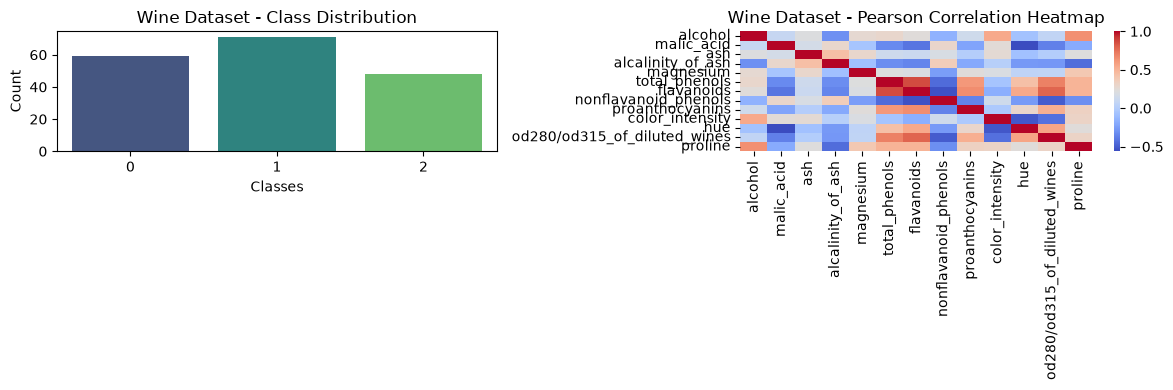

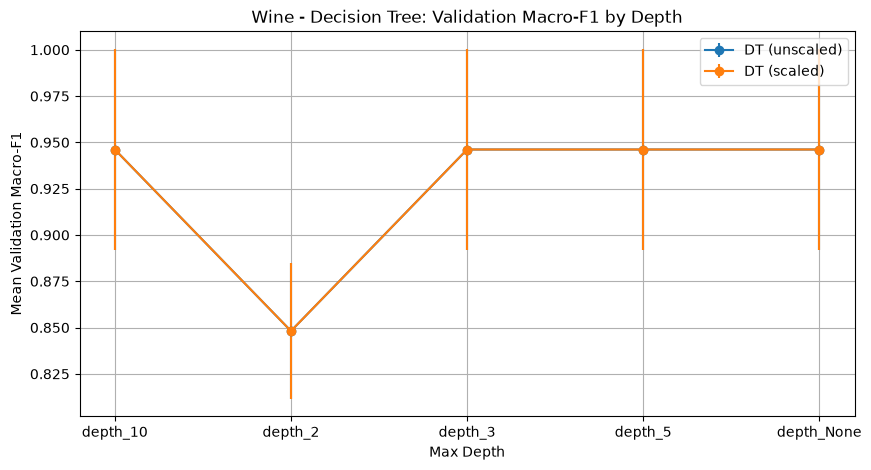

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Wine Sınıf Dağılımı ve Korelasyon Isı Haritası
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.countplot(x=y_wine, palette='viridis')
plt.title('Wine Dataset - Class Distribution')
plt.xlabel('Classes')
plt.ylabel('Count')

plt.subplot(1, 2, 2)
sns.heatmap(X_wine.corr(), cmap='coolwarm', annot=False)
plt.title('Wine Dataset - Pearson Correlation Heatmap')
plt.tight_layout()
plt.show()

# 2. Wine Parametre Kıyaslama Eğrileri (Decision Tree ve KNN için ortalama macro-F1 ve hata çubukları)
# (Önceki hücrelerden üretilen df_wine_runs üzerinden özet hesaplama)
summary_wine = df_wine_runs.groupby(['algorithm', 'representation', 'parameter'])['val_macro_f1'].agg(['mean', 'std']).reset_index()

plt.figure(figsize=(10, 5))
dt_summary = summary_wine[summary_wine['algorithm'] == 'DecisionTree']
for rep in ['unscaled', 'scaled']:
    sub = dt_summary[dt_summary['representation'] == rep]
    # Parametreleri sıralı dizelim
    plt.errorbar([str(p) for p in sub['parameter']], sub['mean'], yerr=sub['std'], marker='o', label=f'DT ({rep})')

plt.title('Wine - Decision Tree: Validation Macro-F1 by Depth')
plt.xlabel('Max Depth')
plt.ylabel('Mean Validation Macro-F1')
plt.legend()
plt.grid(True)
plt.show()

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_wine

# 1. Wine verisini ve train/test ayrımını doğrudan güvenli bir şekilde yapalım
wine = load_wine()
X_wine = pd.DataFrame(wine.data, columns=wine.feature_names)
y_wine = wine.target

# %80 Train-Val ve %20 Test (Seed 42)
X_tr_val_w, X_test_w, y_tr_val_w, y_test_w = train_test_split(
    X_wine, y_wine, test_size=0.20, stratify=y_wine, random_state=42
)

# Seed 42 için 70% Train / 10% Validation ayırımı
X_train, X_val, y_train, y_val = train_test_split(
    X_tr_val_w, y_tr_val_w, test_size=0.125, stratify=y_tr_val_w, random_state=42
)

print("✅ X_train başarıyla tanımlandı! Shape:", X_train.shape)

✅ X_train başarıyla tanımlandı! Shape: (124, 13)


🎯 Seçilen Wine Model: KNN (scaled, k_7)

--- Wine Classification Report ---
              precision    recall  f1-score   support

           0       0.92      1.00      0.96        12
           1       1.00      0.93      0.96        14
           2       1.00      1.00      1.00        10

    accuracy                           0.97        36
   macro avg       0.97      0.98      0.97        36
weighted avg       0.97      0.97      0.97        36



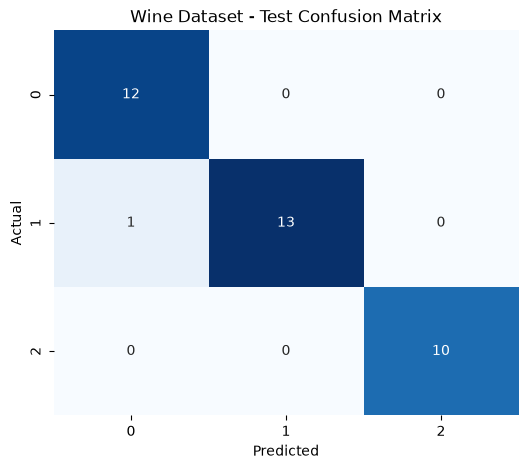

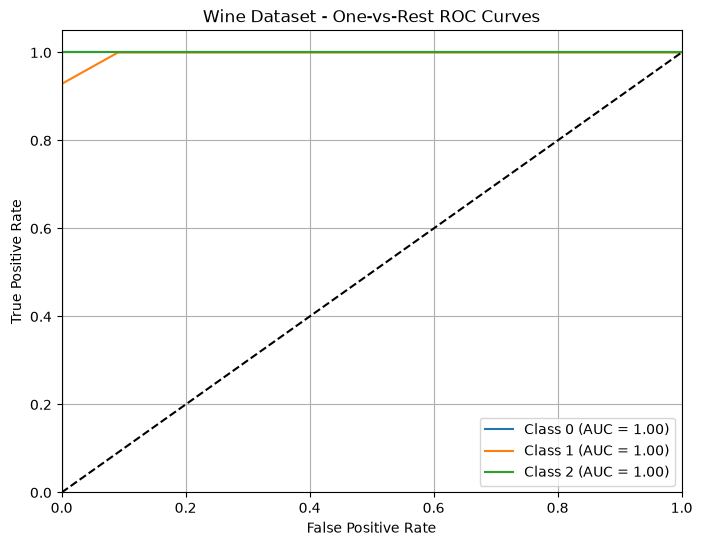

✅ Wine test ve görselleştirme adımları başarıyla tamamlandı!


In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
from sklearn.preprocessing import label_binarize

# 1. classifier_summary tablosunu doğrudan df_wine_runs üzerinden oluşturalım
summary_cols = ['val_accuracy', 'val_precision', 'val_recall', 'val_macro_f1', 'val_roc_auc']
classifier_summary = df_wine_runs.groupby(['dataset', 'algorithm', 'representation', 'parameter'])[summary_cols].agg(['mean', 'std']).reset_index()
classifier_summary.columns = ['_'.join(col).strip('_') for col in classifier_summary.columns.values]
classifier_summary = classifier_summary.rename(columns={'dataset_': 'dataset', 'algorithm_': 'algorithm', 'representation_': 'representation', 'parameter_': 'parameter'})

# 2. En iyi modelin seed 42 versiyonu ile test seti değerlendirmesi
best_wine_row = classifier_summary[(classifier_summary['dataset']=='wine')].sort_values(by='val_macro_f1_mean', ascending=False).iloc[0]
print(f"🎯 Seçilen Wine Model: {best_wine_row['algorithm']} ({best_wine_row['representation']}, {best_wine_row['parameter']})")

# 3. Scaled veriyi bu hücre içinde güvenli bir şekilde oluşturalım
scaler_wine_42 = StandardScaler()
X_tr_s42_scaled = pd.DataFrame(
    scaler_wine_42.fit_transform(X_train), 
    columns=X_wine.columns, 
    index=X_train.index
)

# Test setini de seed 42 scaler ile ölçeklendirelim
X_test_scaled_w = pd.DataFrame(
    scaler_wine_42.transform(X_test_w), 
    columns=X_wine.columns, 
    index=X_test_w.index
)

# 4. Model eğitimi (Seed 42)
rep_type = best_wine_row['representation']
X_tr_final = X_train if rep_type == 'unscaled' else X_tr_s42_scaled
X_test_final = X_test_w if rep_type == 'unscaled' else X_test_scaled_w
y_tr_final = y_train

if best_wine_row['algorithm'] == 'DecisionTree':
    depth_val = None if 'None' in str(best_wine_row['parameter']) else int(best_wine_row['parameter'].split('_')[1])
    final_wine_model = DecisionTreeClassifier(max_depth=depth_val, random_state=42)
elif best_wine_row['algorithm'] == 'KNN':
    k_val = int(best_wine_row['parameter'].split('_')[1])
    final_wine_model = KNeighborsClassifier(n_neighbors=k_val, weights='uniform', metric='euclidean')
else:
    final_wine_model = GaussianNB()

final_wine_model.fit(X_tr_final, y_tr_final)
y_test_pred = final_wine_model.predict(X_test_final)
y_test_proba = final_wine_model.predict_proba(X_test_final)

# 5. Classification Report ve Confusion Matrix
print("\n--- Wine Classification Report ---")
print(classification_report(y_test_w, y_test_pred, zero_division=0))

plt.figure(figsize=(6, 5))
cm_wine = confusion_matrix(y_test_w, y_test_pred)
sns.heatmap(cm_wine, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Wine Dataset - Test Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# 6. Wine OvR ROC Curves
y_test_bin = label_binarize(y_test_w, classes=[0, 1, 2])
plt.figure(figsize=(8, 6))
for i in range(3):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_test_proba[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'Class {i} (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Wine Dataset - One-vs-Rest ROC Curves')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()
print("✅ Wine test ve görselleştirme adımları başarıyla tamamlandı!")